# Home Credit Default Risk

Goal: predict whether a given data entry (representing a customer) is likely to default (= fail to make a required payment) on their loan based on a variety of customer data provide. The task is to create a machine learning model that best predicts the probability of default for each customer.

## 1. Setup


### 1.1 Importing Libraries

In [ ]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, TargetEncoder

import warnings 
warnings.filterwarnings('ignore')

check if the path is correctly set

In [2]:
import os 
from pathlib import Path

current_dir = Path(os.getcwd())

train_file = current_dir/"input"/"train.csv"
test_file = current_dir/"input"/"test.csv"
sample_sub_file = current_dir/"input"/"sample_submission.csv"

if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


## 2. Loading the Data

### 2.1 Data Overview

In [3]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

Brief overview of the data

In [4]:
# train data
print(f"train shape: {train.shape}")
train.head()

train shape: (171202, 34)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1


In [5]:
# test data
print(f"test shape: {test.shape}")
test.head()

test shape: (61500, 33)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0
3,171205,Revolving loans,F,2,225000.0,450000.0,22500.0,450000.0,Working,Higher education,...,2,Business Entity Type 3,NaN,0.470384,0.217629,-442.0,0.0,0.0,0.0,3.0
4,171206,Cash loans,F,2,144000.0,545040.0,26640.0,450000.0,Working,Higher education,...,3,Business Entity Type 3,0.269931,0.373133,NaN,-1333.0,0.0,0.0,0.0,3.0


Excluding the TARGET column in train data and the SK_ID_CURR which represents ID number, there are 32 types of features

### 2.2 Feature Selection

Based on the data dictionary (`HomeCredit_columns_description.xlsx`), 19 high-signal features were selected across four domain pillars:

* **External Credit Scores:** `EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCE_3` — Normalized risk scores from external credit bureaus.
* **Financial Capacity & Contract Terms:** `AMT_CREDIT`, `AMT_ANNUITY`, `AMT_INCOME_TOTAL`, `AMT_GOODS_PRICE`, `NAME_CONTRACT_TYPE`, `OWN_CAR_AGE` — Core variables for evaluating debt-to-income capacity and asset ownership.
* **Temporal Stability:** `DAYS_BIRTH`, `DAYS_EMPLOYED`, `DAYS_ID_PUBLISH`, `DAYS_LAST_PHONE_CHANGE` — Age and employment tenure typically show a strong negative correlation with default risk.
* **Socioeconomic Profile:** `NAME_EDUCATION_TYPE`, `CODE_GENDER`, `NAME_INCOME_TYPE`, `OCCUPATION_TYPE`, `REGION_RATING_CLIENT`, `ORGANIZATION_TYPE` — Capture structural risk differences across demographics, occupation, and region.




In [6]:
use_features = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_INCOME_TOTAL",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "DAYS_ID_PUBLISH",
    "DAYS_LAST_PHONE_CHANGE",
    "NAME_EDUCATION_TYPE",
    "CODE_GENDER",
    "NAME_INCOME_TYPE",
    "NAME_CONTRACT_TYPE",
    "OCCUPATION_TYPE",
    "OWN_CAR_AGE",
    "ORGANIZATION_TYPE",
    "REGION_RATING_CLIENT"
]

target = train["TARGET"].values

train = train[use_features]
train["TARGET"] = target
test = test[use_features]

check the data once again

In [7]:
print(f"train_shape: {train.shape}")
print(train.columns)
train.head()

train_shape: (171202, 20)
Index(['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AMT_CREDIT',
       'AMT_ANNUITY', 'AMT_INCOME_TOTAL', 'AMT_GOODS_PRICE', 'DAYS_BIRTH',
       'DAYS_EMPLOYED', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE',
       'NAME_EDUCATION_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE',
       'NAME_CONTRACT_TYPE', 'OCCUPATION_TYPE', 'OWN_CAR_AGE',
       'ORGANIZATION_TYPE', 'REGION_RATING_CLIENT', 'TARGET'],
      dtype='object')


,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,AMT_CREDIT,AMT_ANNUITY,AMT_INCOME_TOTAL,AMT_GOODS_PRICE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_ID_PUBLISH,DAYS_LAST_PHONE_CHANGE,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,NAME_CONTRACT_TYPE,OCCUPATION_TYPE,OWN_CAR_AGE,ORGANIZATION_TYPE,REGION_RATING_CLIENT,TARGET
0,NaN,0.372591,NaN,755190.0,36328.5,112500.0,675000.0,-9233,-878,-522,-292.0,Higher education,F,Working,Cash loans,Core staff,NaN,School,2,0
1,NaN,0.449567,0.553165,585000.0,16893.0,225000.0,585000.0,-20148,365243,-3436,-617.0,Secondary / secondary special,F,Pensioner,Cash loans,Other,NaN,XNA,2,0
2,NaN,0.569503,NaN,334152.0,18256.5,54000.0,270000.0,-18496,-523,-2050,-542.0,Secondary / secondary special,F,State servant,Cash loans,Core staff,NaN,Postal,2,0
3,NaN,0.105235,0.767523,152820.0,8901.0,67500.0,135000.0,-24177,365243,-3951,0.0,Lower secondary,F,Pensioner,Cash loans,Other,NaN,XNA,3,0
4,0.342344,0.202490,0.669057,271066.5,21546.0,157500.0,234000.0,-10685,-697,-3226,-1243.0,Secondary / secondary special,M,Commercial associate,Cash loans,Drivers,NaN,Business Entity Type 3,3,1


In [8]:
print(f"test_shape: {test.shape}")
print(test.columns)
test.head()

test_shape: (61500, 19)
Index(['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AMT_CREDIT',
       'AMT_ANNUITY', 'AMT_INCOME_TOTAL', 'AMT_GOODS_PRICE', 'DAYS_BIRTH',
       'DAYS_EMPLOYED', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE',
       'NAME_EDUCATION_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE',
       'NAME_CONTRACT_TYPE', 'OCCUPATION_TYPE', 'OWN_CAR_AGE',
       'ORGANIZATION_TYPE', 'REGION_RATING_CLIENT'],
      dtype='object')


,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,AMT_CREDIT,AMT_ANNUITY,AMT_INCOME_TOTAL,AMT_GOODS_PRICE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_ID_PUBLISH,DAYS_LAST_PHONE_CHANGE,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,NAME_CONTRACT_TYPE,OCCUPATION_TYPE,OWN_CAR_AGE,ORGANIZATION_TYPE,REGION_RATING_CLIENT
0,NaN,0.720416,NaN,961146.0,28233.0,144000.0,688500.0,-12108,-2372,-3022,-1.0,Higher education,F,Working,Cash loans,Medicine staff,NaN,Kindergarten,2
1,NaN,0.287306,NaN,296280.0,16069.5,103500.0,225000.0,-17907,-1712,-253,-212.0,Secondary / secondary special,F,Working,Cash loans,Cleaning staff,NaN,School,2
2,NaN,0.352456,0.389339,183694.5,11236.5,180000.0,139500.0,-15221,-553,-4495,-428.0,Secondary / secondary special,F,Commercial associate,Cash loans,Other,NaN,Trade: type 7,3
3,NaN,0.470384,0.217629,450000.0,22500.0,225000.0,450000.0,-11217,-1438,-1189,-442.0,Higher education,F,Working,Revolving loans,Other,NaN,Business Entity Type 3,2
4,0.269931,0.373133,NaN,545040.0,26640.0,144000.0,450000.0,-11415,-2362,-1728,-1333.0,Higher education,F,Working,Cash loans,Other,14.0,Business Entity Type 3,3


## 3. Visualizing and Understanding the Data

Section to visualizing and analyzing, to deepen the understanding of data distribution, missing values, outliers, correlations, and etc. The results of the analysis obtained at this stage will be useful for preprocessing, feature creation, and selection of machine learning models, which are all imoortant to building modelos with better prediction ability.

### 3.1 Checking Missing Values

In [9]:
train.isnull().sum()

EXT_SOURCE_1              118928
EXT_SOURCE_2                 369
EXT_SOURCE_3               54586
AMT_CREDIT                     0
AMT_ANNUITY                    0
AMT_INCOME_TOTAL               0
AMT_GOODS_PRICE                0
DAYS_BIRTH                     0
DAYS_EMPLOYED                  0
DAYS_ID_PUBLISH                0
DAYS_LAST_PHONE_CHANGE         0
NAME_EDUCATION_TYPE            0
CODE_GENDER                    0
NAME_INCOME_TYPE               0
NAME_CONTRACT_TYPE             0
OCCUPATION_TYPE                0
OWN_CAR_AGE               112992
ORGANIZATION_TYPE              0
REGION_RATING_CLIENT           0
TARGET                         0
dtype: int64

In [10]:
test.isnull().sum()

EXT_SOURCE_1              42912
EXT_SOURCE_2                130
EXT_SOURCE_3              19690
AMT_CREDIT                    0
AMT_ANNUITY                   0
AMT_INCOME_TOTAL              0
AMT_GOODS_PRICE               0
DAYS_BIRTH                    0
DAYS_EMPLOYED                 0
DAYS_ID_PUBLISH               0
DAYS_LAST_PHONE_CHANGE        0
NAME_EDUCATION_TYPE           0
CODE_GENDER                   0
NAME_INCOME_TYPE              0
NAME_CONTRACT_TYPE            0
OCCUPATION_TYPE               0
OWN_CAR_AGE               40909
ORGANIZATION_TYPE             0
REGION_RATING_CLIENT          0
dtype: int64

**Missing Value Insights (MNAR — Missing Not At Random):**
* **`OWN_CAR_AGE` (~66% missing):** Null values indicate applicants who do not own a vehicle.
* **`EXT_SOURCE_1` (~69% missing) & `EXT_SOURCE_3` (~32% missing):** Missingness itself carries strong predictive signal. *Thin-file* applicants (with no external bureau history) typically exhibit a distinct default profile compared to clients with established credit scores.


### 3.2 Visualization and analysis of each feature

#### 3.2.1 TARGET

The target variable (`TARGET`) is heavily imbalanced, with default cases (`1`) representing a small minority of the dataset (~8%). Consequently, **accuracy is not a suitable metric** (a naive model predicting `0` for all cases would achieve ~92% accuracy). Therefore, **ROC-AUC** is used as the primary evaluation metric. Techniques such as SMOTE or undersampling are intentionally avoided to preserve true default probability calibration.

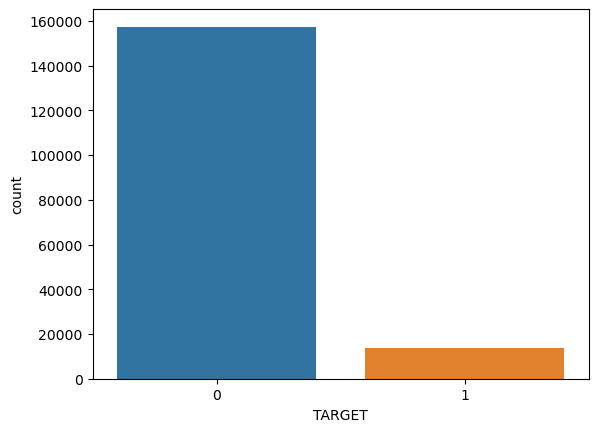

In [11]:
sns.countplot(data = train, x = "TARGET")
plt.show()

In [12]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 20 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   EXT_SOURCE_1            52274 non-null   float64
 1   EXT_SOURCE_2            170833 non-null  float64
 2   EXT_SOURCE_3            116616 non-null  float64
 3   AMT_CREDIT              171202 non-null  float64
 4   AMT_ANNUITY             171202 non-null  float64
 5   AMT_INCOME_TOTAL        171202 non-null  float64
 6   AMT_GOODS_PRICE         171202 non-null  float64
 7   DAYS_BIRTH              171202 non-null  int64  
 8   DAYS_EMPLOYED           171202 non-null  int64  
 9   DAYS_ID_PUBLISH         171202 non-null  int64  
 10  DAYS_LAST_PHONE_CHANGE  171202 non-null  float64
 11  NAME_EDUCATION_TYPE     171202 non-null  object 
 12  CODE_GENDER             171202 non-null  object 
 13  NAME_INCOME_TYPE        171202 non-null  object 
 14  NAME_CONTRACT_TYPE  

#### 3.2.2 EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3

All three features represent normalized credit scores from external bureaus, exhibiting well-behaved distributions strictly bounded within the `[0, 1]` interval with no extreme outliers.

* **Predictive Signal & Missingness (MNAR):** While `EXT_SOURCE_2` is nearly complete (~0.2% missing), `EXT_SOURCE_1` (~69.5% missing) and `EXT_SOURCE_3` (~31.9% missing) have substantial missingness. In credit scoring, this absence is **Missing Not At Random (MNAR)**—it typically identifies *thin-file* applicants with limited or no external credit history.
* **Preprocessing Strategy:** `EXT_SOURCE_2` will receive simple median imputation, whereas `EXT_SOURCE_1` and `EXT_SOURCE_3` will be imputed with the median alongside binary missingness indicators (`_IS_MISSING`) to preserve the risk signal carried by the absence of bureau data.

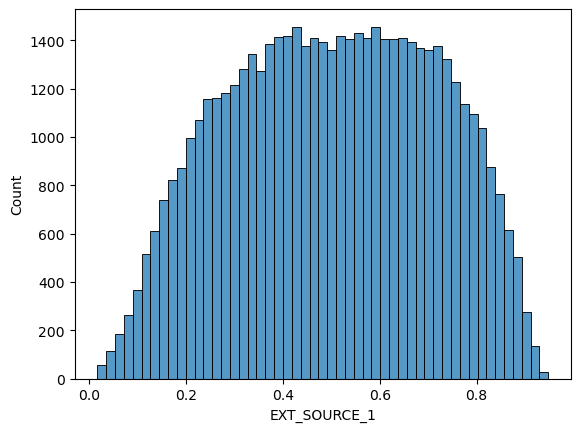

In [13]:
sns.histplot(data = train, x = "EXT_SOURCE_1")
plt.show()

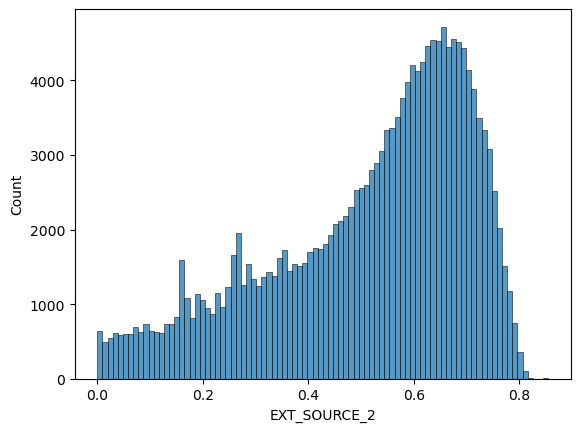

In [14]:
sns.histplot(data = train, x = "EXT_SOURCE_2")
plt.show()

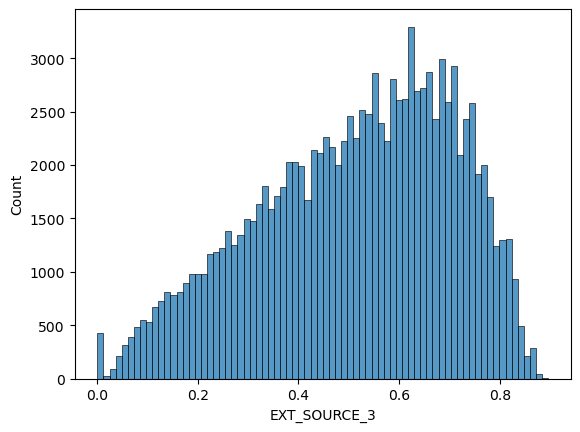

In [15]:
sns.histplot(data = train, x = "EXT_SOURCE_3")
plt.show()

#### 3.2.3 AMT_CREDIT, AMT_ANNUITY, AMT_INCOME_TOTAL, AMT_GOODS_PRICE

Unlike `AMT_INCOME_TOTAL`, these three variables exhibit well-behaved distributions and require no outlier or rounding treatment. This difference stems from data provenance: while total income is self-declared by the applicant (making it prone to rounding and extreme reporting errors), credit amount, loan annuity, and goods price are generated and validated directly by the financial institution's internal systems.

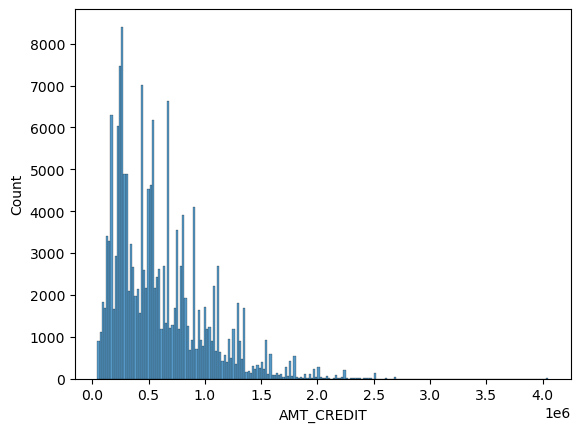

In [16]:
sns.histplot(data = train, x = "AMT_CREDIT")
plt.show()

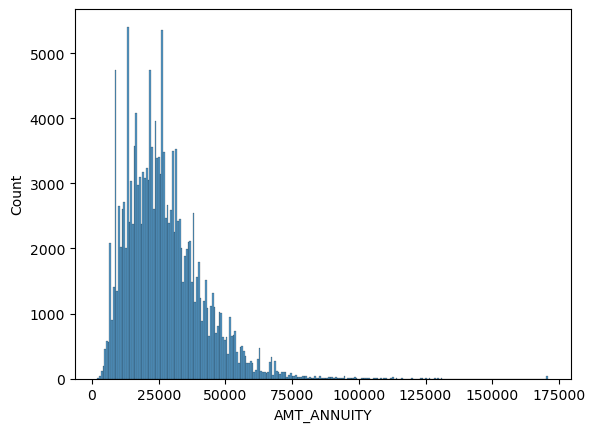

In [17]:
sns.histplot(data = train, x = "AMT_ANNUITY")
plt.show()

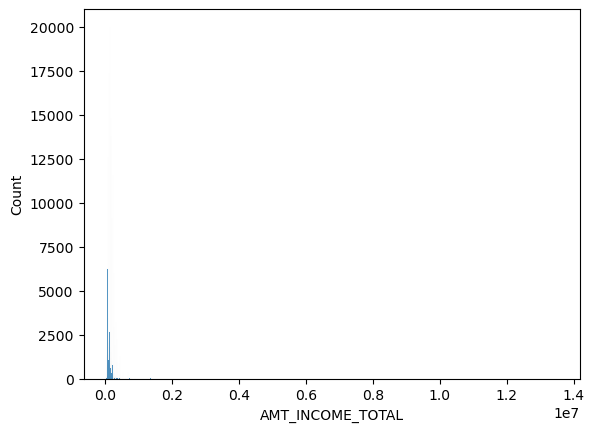

In [18]:
sns.histplot(data = train, x = "AMT_INCOME_TOTAL")
plt.show()

Because the presence of outliers, this graphic is so difficult to interpret. Soon, will be apply a logaritic tranformation

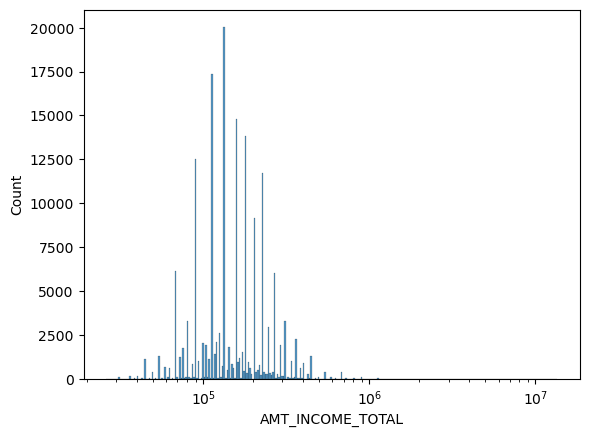

In [19]:
sns.histplot(data = train, x = "AMT_INCOME_TOTAL", log_scale = 10)
plt.show()

The income is supposed to be a continuous value, but it looks like a discrete value. Below, it will be checked

In [20]:
len(train["AMT_INCOME_TOTAL"].unique())

1641

In [21]:
train["AMT_INCOME_TOTAL"].value_counts().head(10)

135000.0    19969
112500.0    17320
157500.0    14772
180000.0    13791
90000.0     12481
225000.0    11573
202500.0     9128
67500.0      6130
270000.0     6006
81000.0      3295
Name: AMT_INCOME_TOTAL, dtype: int64

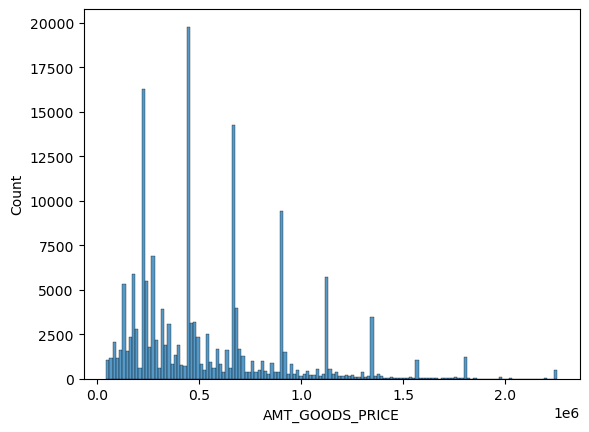

In [22]:
sns.histplot(data = train, x = "AMT_GOODS_PRICE")
plt.show()

#### 3.2.4 DAYS_BIRTH, DAYS_EMPLOYED, DAYS_ID_PUBLISH, DAYS_LAST_PHONE_CHANGE

- DAYS_BIRTH is recorded as negative days relative to the loan application date, ranging from approximately -25,200 days (approximately 69 years old) to -7,500 days (20.5 years old). In next session it can inspect it in positive years.
- DAYS_EMPLOYED presents higher values than the most (0 and lower). That's occur because in some systems, when the person is a pensioner or unemployed, the number above 350,000 is used like a placeholder (to indicate approximatelly 1000 years).
- DAYS_ID_PUBLISH: This data has a peak between -4000 and -5000, but the grafic in general goes from 0 to -6,300 days (approximately 17.2 years). In some countries the national identification document has mandatory renewal at fixed ages or a ten-year validity. This peak concentrates exactly the large demographic group that renewed the mandatory document just over a decade before the loan.

- DAYS_LAST_PHONE_CHANGE: this data has a peak in 0 because 0 meaning customers who have never changed their mobile phone/number since opening an account with the financial institution.

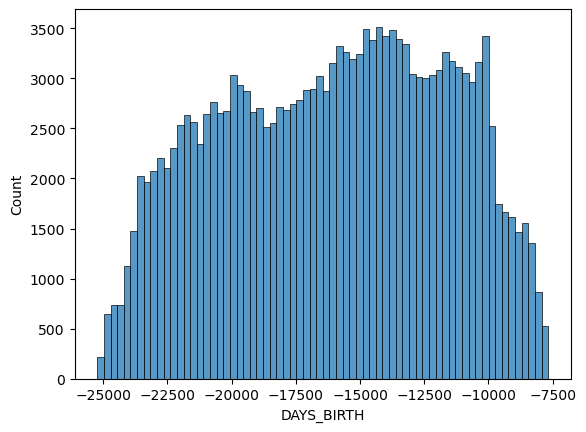

In [23]:
sns.histplot(data = train, x = "DAYS_BIRTH")
plt.show()

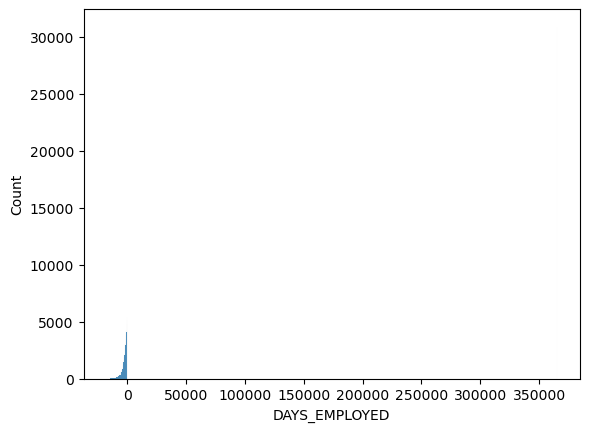

In [24]:
sns.histplot(data = train, x = "DAYS_EMPLOYED")
plt.show()

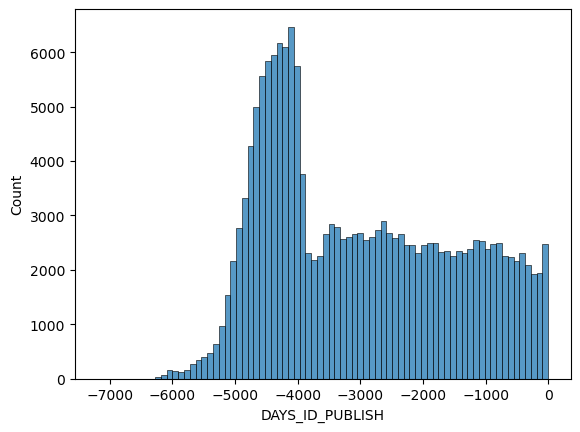

In [25]:
sns.histplot(data = train, x = "DAYS_ID_PUBLISH")
plt.show()

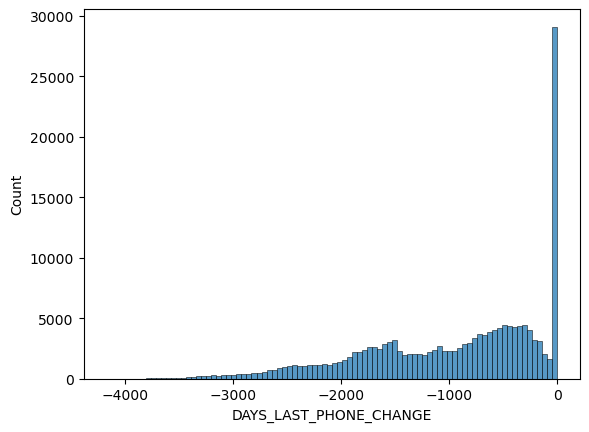

In [26]:
sns.histplot(data = train, x = "DAYS_LAST_PHONE_CHANGE")
plt.show()

#### 3.2.5 NAME_EDUCATION_TYPE

Applicants are heavily concentrated in *Secondary / secondary special* and *Higher education*. Because education level follows a natural hierarchy, it will be encoded as an ordinal feature in the preprocessing stage.

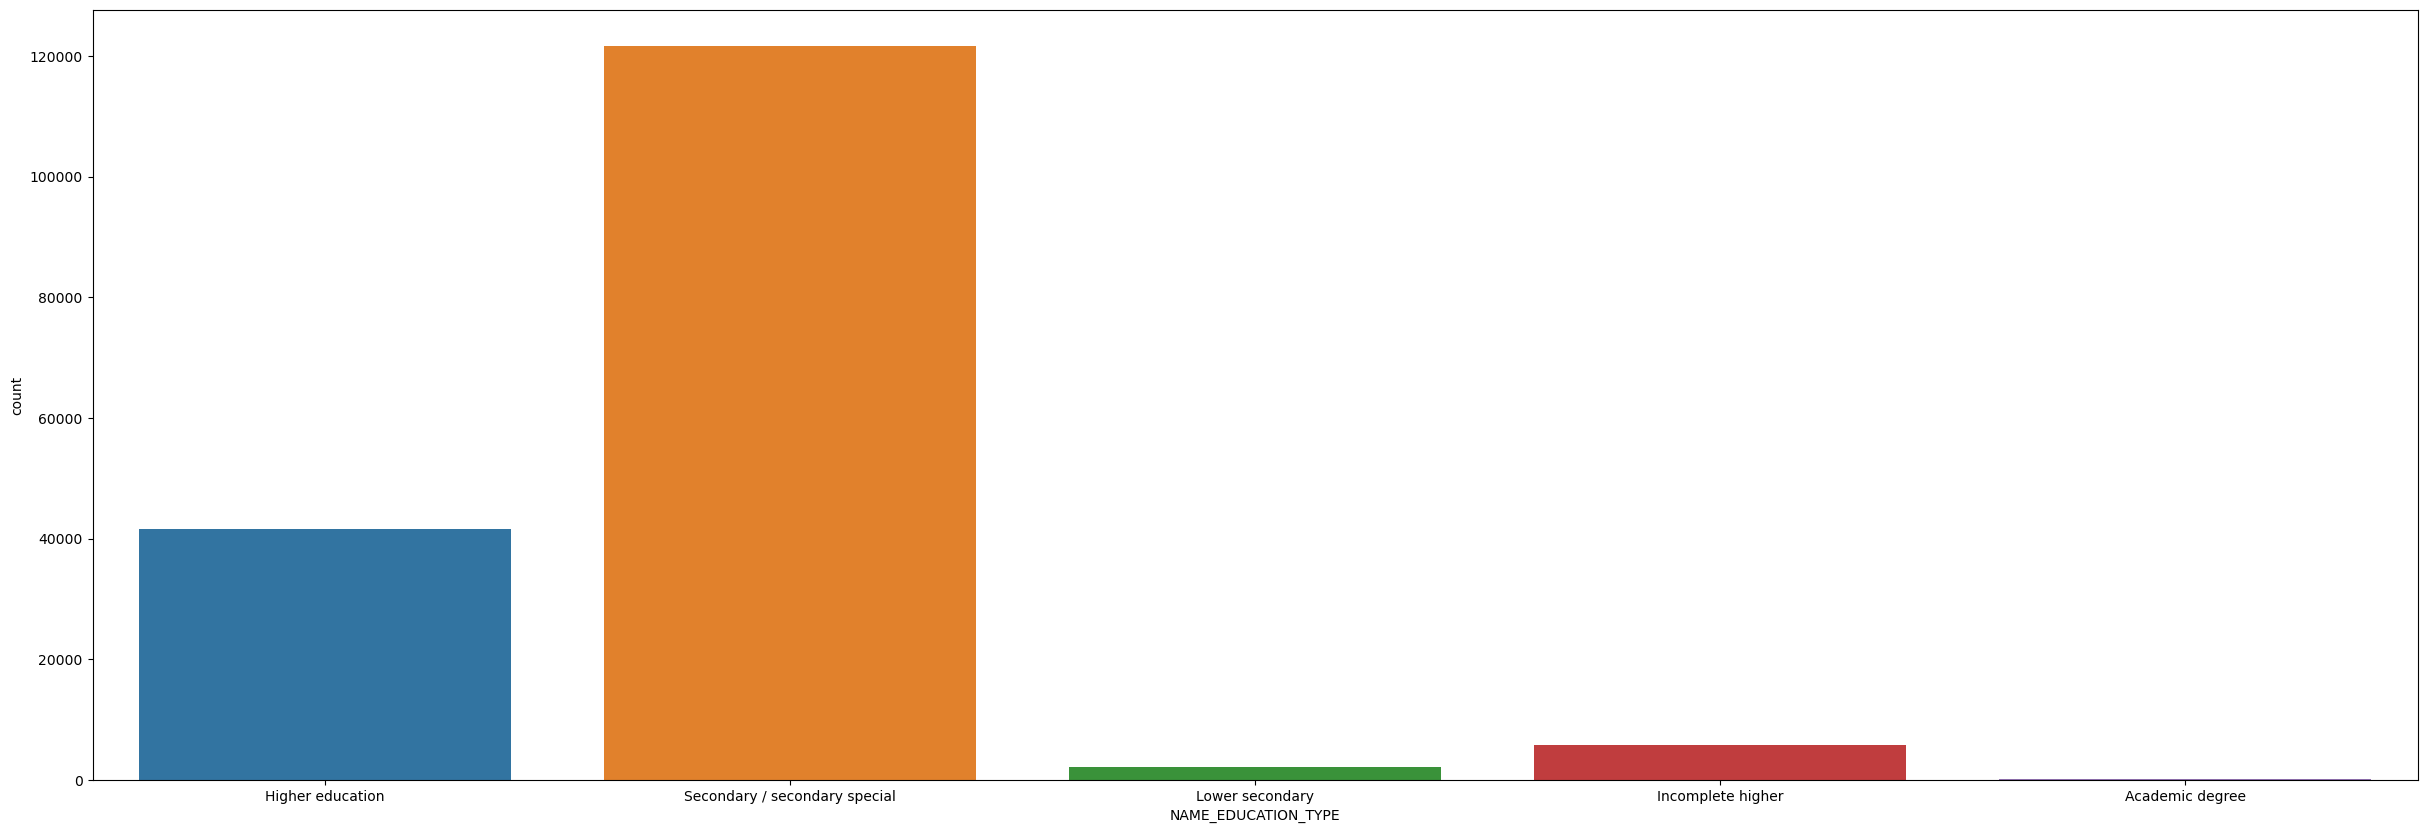

In [27]:
plt.figure(figsize=(30,10))
sns.countplot(data = train, x = "NAME_EDUCATION_TYPE")
plt.show()

#### 3.2.6 CODE GENDER

The CODE_GENDER distribution shows that female applicants outnumber male applicants by nearly 2 to 1. Additionally, there is a negligible third category XNA which will treated in next session.

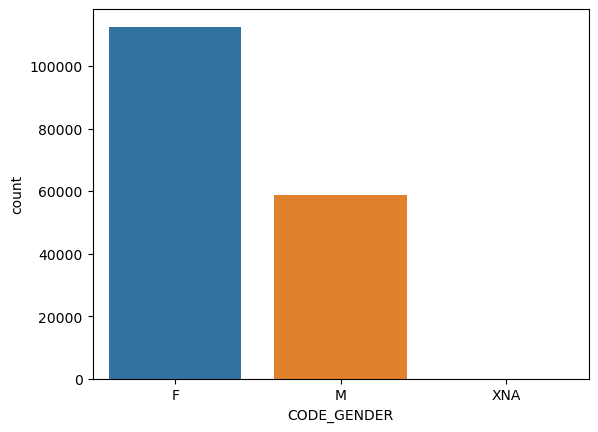

In [28]:
sns.countplot(data = train, x = "CODE_GENDER")
plt.show()

#### 3.2.7 NAME_INCOME_TYPE

In NAME_INCOME_TYPE the concentration of variables appear in 4 main categories: working, commercial associate, pensioner and state servant. Meanwhile, Student, Businessman, Maternity leave and Unemployed together account a little amount of records. Because this, it will be consolidate the four rare classes into an 'Other' category (it'll be in next session)

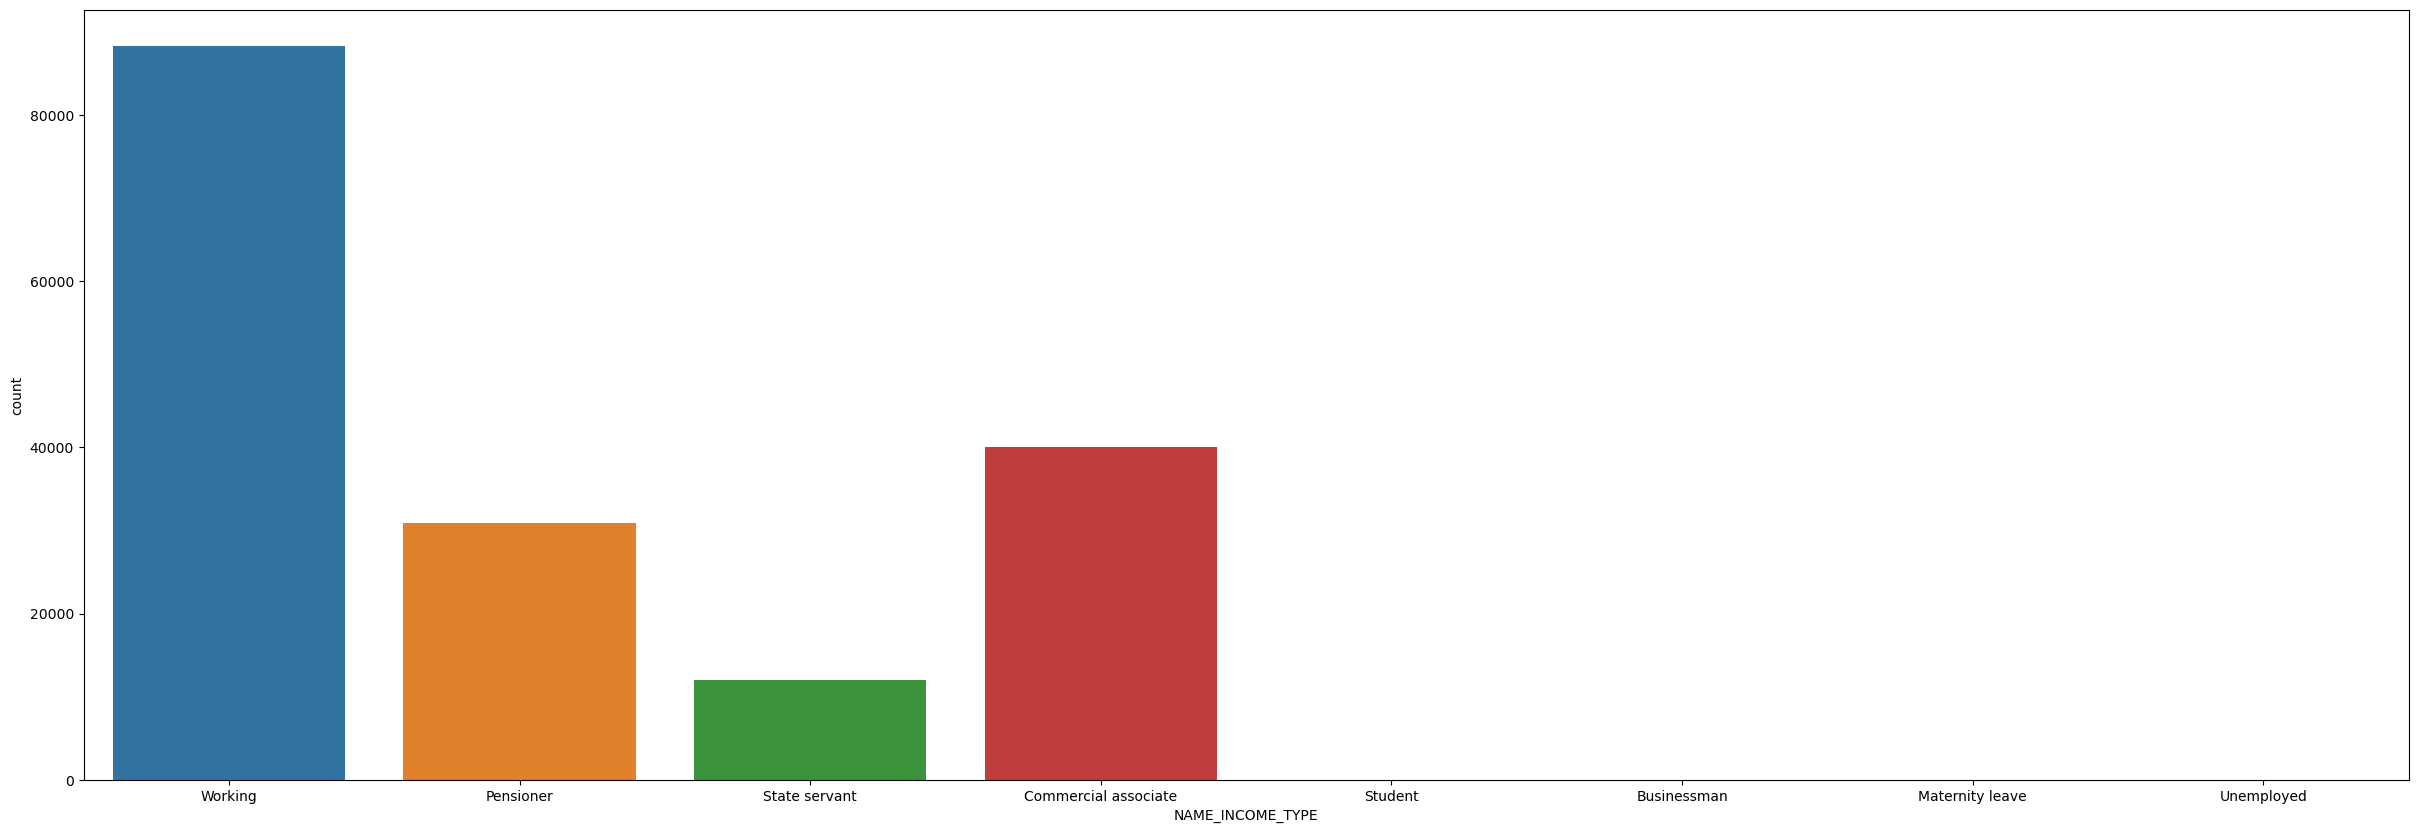

In [29]:
plt.figure(figsize = (30,10))
sns.countplot(data = train, x = "NAME_INCOME_TYPE")
plt.show()

#### 3.2.8 NAME_CONTRACT_TYPE

The NAME_CONTRACT_TYPE is a binary categorical feature. This data is ok, and will be change to numerical type in next session.

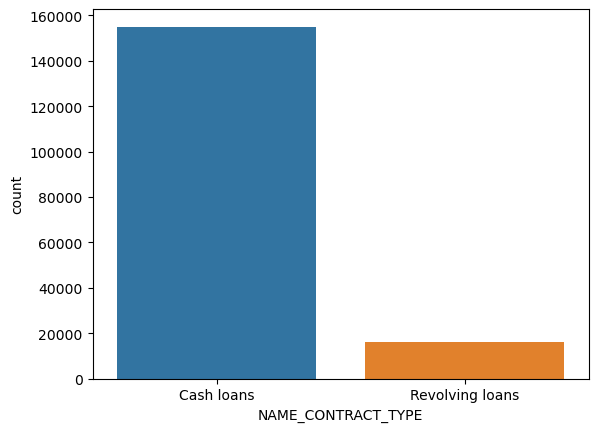

In [30]:
sns.countplot(data = train, x = "NAME_CONTRACT_TYPE")
plt.show()

#### 3.2.9 OCCUPATION_TYPE

To reduce sparsity and prevent overfitting on rare job titles while preserving socioeconomic risk signals, professions with fewer than **1,500 records** were aggregated into two domain-aligned groups:
* **`Other_Office_Staff`:** `IT staff`, `HR staff`, `Realty agents`, and `Secretaries`.
* **`Other_Service_Labor`:** `Waiters/barmen staff`, `Low-skill Laborers`, and `Private service staff`.

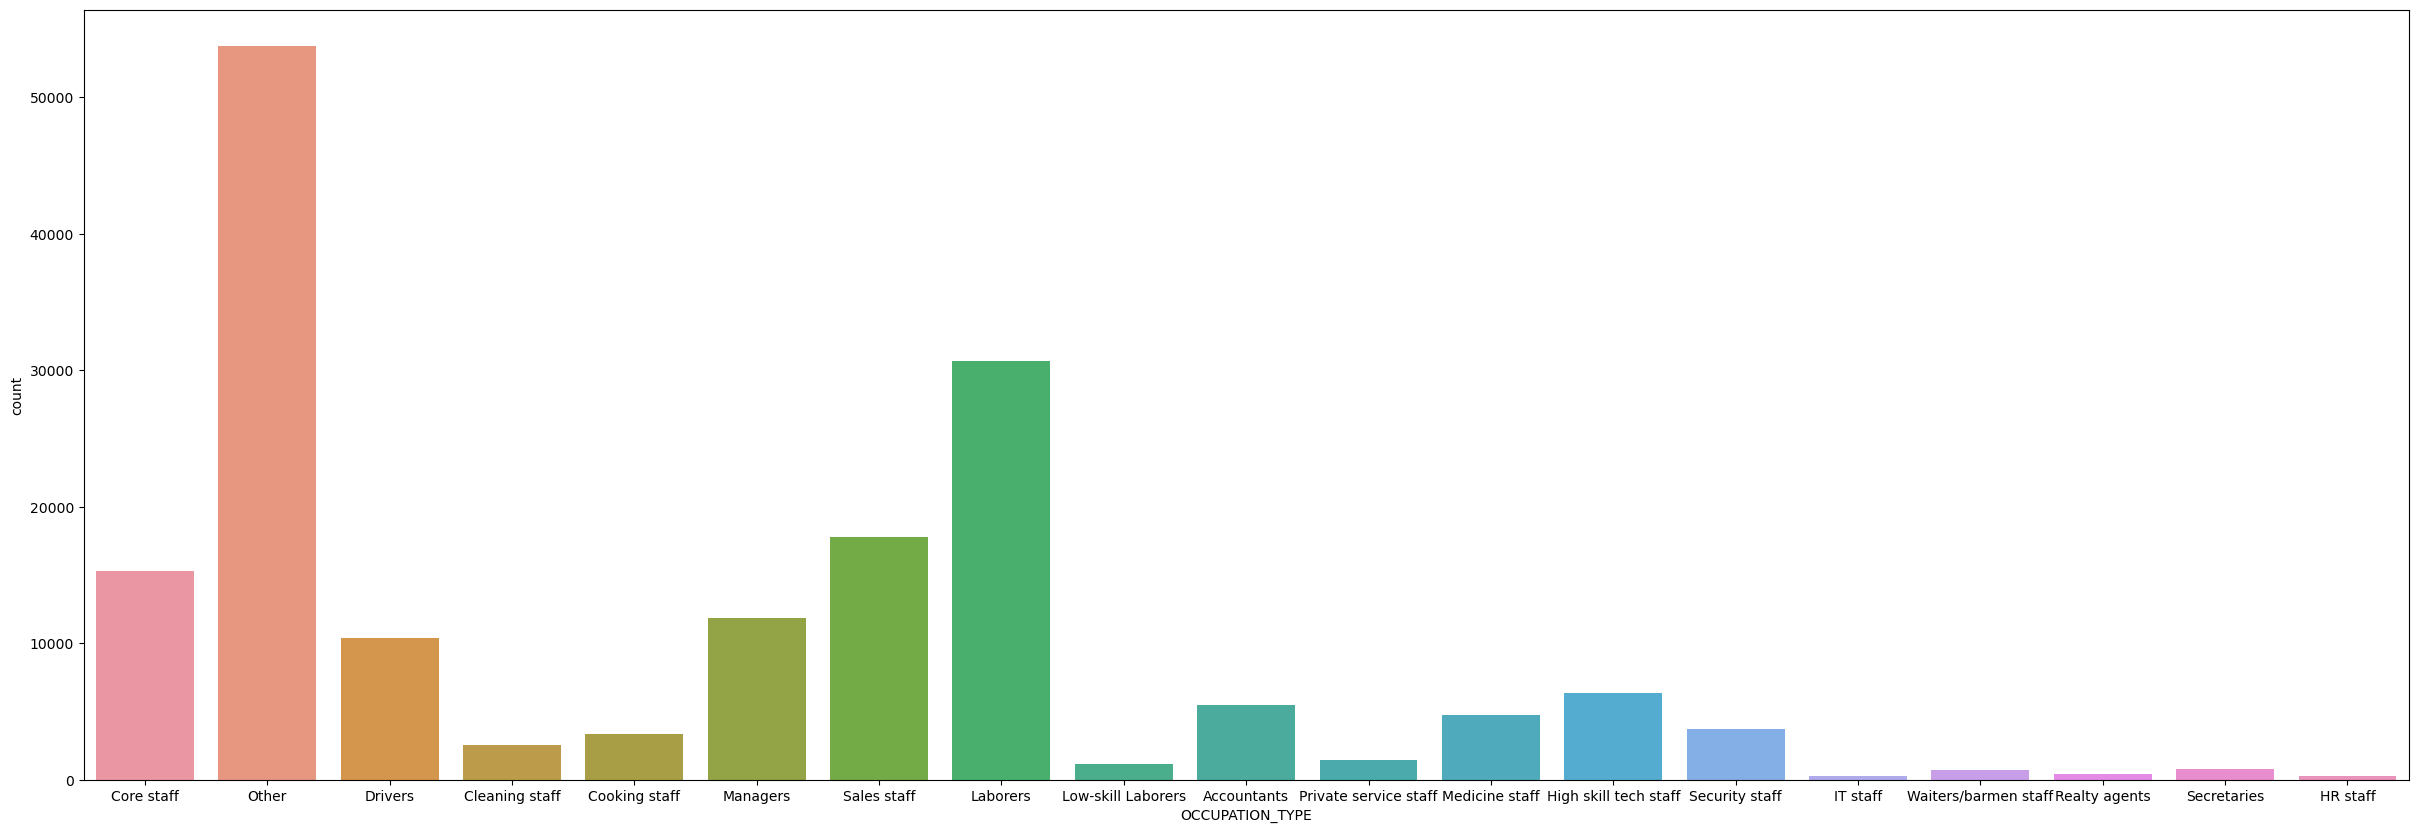

In [31]:
plt.figure(figsize = (30,10))
sns.countplot(data = train, x = "OCCUPATION_TYPE")
plt.show()

#### 3.2.10 OWN_CAR_AGE

The OWN_CAR_AGE is mostly concentrated between 1 and 15 years (peaking around 7 years) and naturally tapers off before 50 years. However, there is an anomalous spike at > 60 values, so, values above 60 will be treated as outliers and will be replaced with NaN values.

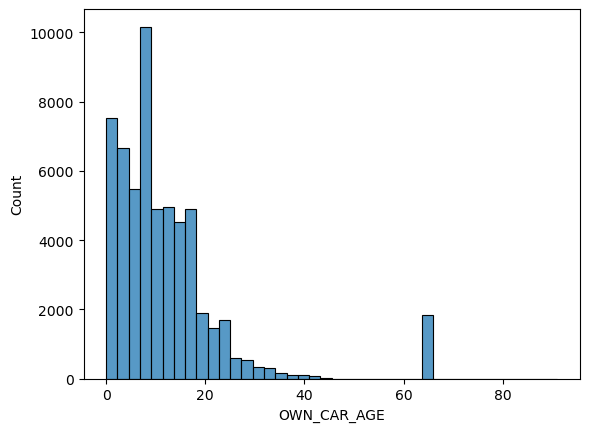

In [32]:
sns.histplot(data = train, x = "OWN_CAR_AGE", bins = 40)
plt.show()

#### 3.2.11 ORGANIZATION_TYPE

To reduce cardinality from **58 raw categories** to **~18 macro-sectors** without artificially inflating the generic `Other` bucket, a three-step domain consolidation was applied:
1. **Explicit Missingness / Placeholder Mapping:** Renamed `XNA` (~30,800 records) to `Unemployed_Pensioner` to reflect its true business meaning.
2. **Hierarchical Consolidation:** Merged numbered subcategories (`Industry: type 1–13`, `Trade: type 1–7`, `Transport: type 1–4`, `Business Entity Type 1–3`) into their respective parent sectors (`Industry`, `Trade`, `Transport`, `Business Entity`).
3. **Rare Category Grouping:** Grouped remaining micro-organizations with fewer than **1,000 records** into `Rare_Organization`.

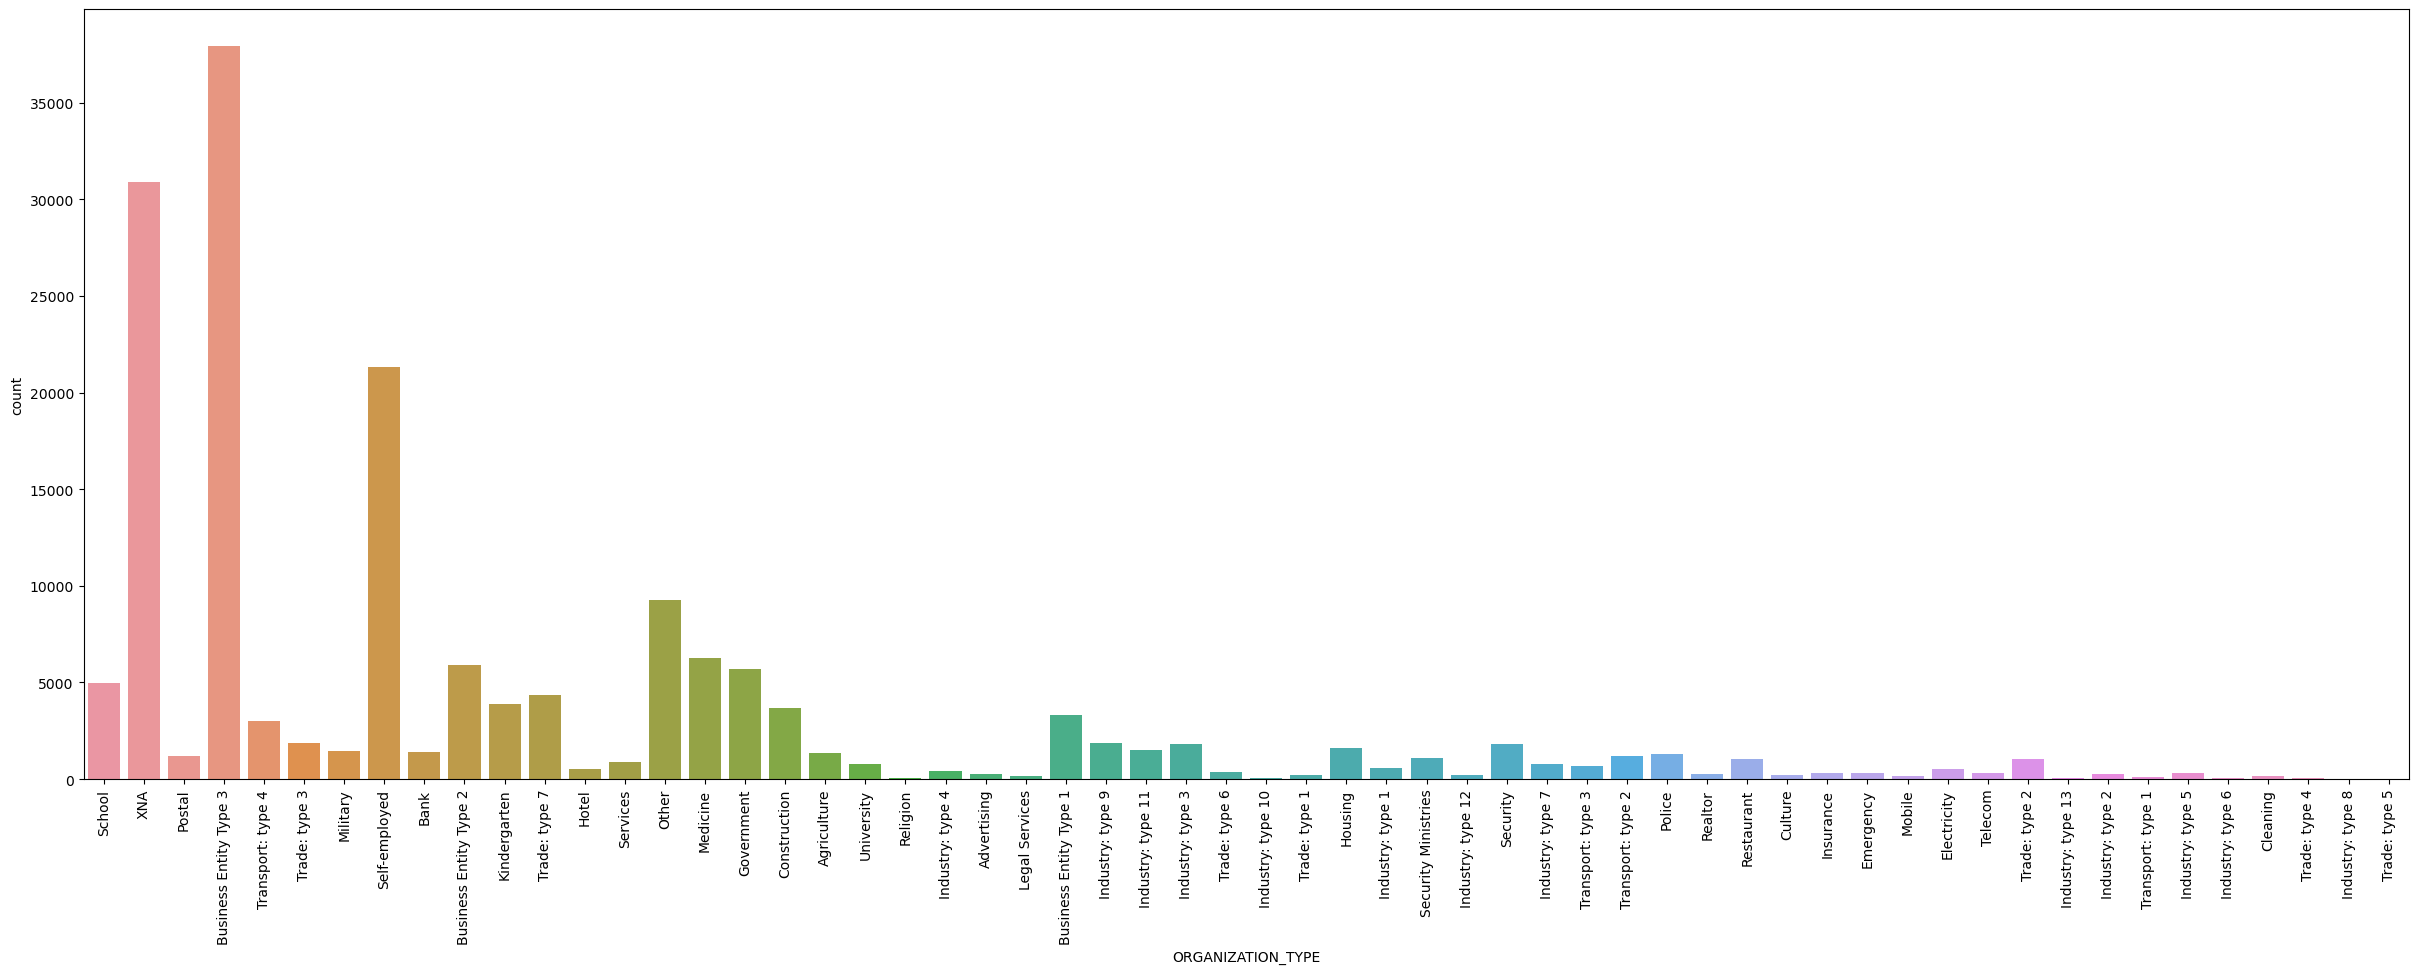

In [33]:
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

#### 3.2.12 REGION_RATING_CLIENT

The REGION_RATING_CLIENT is an ordinal integer feature with most applicants in Rating 2, following by Rating 3 and Rating 1. This feature is ok and no preprocessing is required

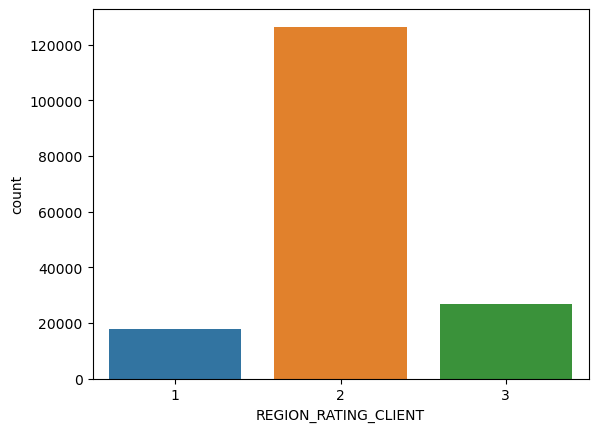

In [34]:
sns.countplot(data = train, x = "REGION_RATING_CLIENT")
plt.show()

## 4. Preprocessing and Feature Creation

### 4.1 Data Cleaning

#### 4.1.1 AMT_INCOME_TOTAL -> apply Clipping (winsorization) in 99.9% percentil

To address extreme income outliers without dropping rows from the test set, it applied upper-bound clipping (Winsorization) at the 99.9th percentile. Crucially, the threshold is computed strictly on the training set and applied to both train and test to prevent data leakage.

In [35]:
# Veryfing the impact before transformation
income_upper_limit = train['AMT_INCOME_TOTAL'].quantile(0.999)

train_outliers_count = (train['AMT_INCOME_TOTAL'] > income_upper_limit).sum()
test_outliers_count = (test['AMT_INCOME_TOTAL'] > income_upper_limit).sum()

print(f'99.9th Percentile Upper Limit: {income_upper_limit:,.2f}')
print(f'Train records capped: {train_outliers_count}')
print(f'Test records capped:  {test_outliers_count}')

99.9th Percentile Upper Limit: 900,000.00
Train records capped: 154
Test records capped:  43


In [36]:
train['AMT_INCOME_TOTAL'] = train['AMT_INCOME_TOTAL'].clip(upper = income_upper_limit)
test['AMT_INCOME_TOTAL'] = test['AMT_INCOME_TOTAL'].clip(upper = income_upper_limit)

<Axes: xlabel='AMT_INCOME_TOTAL', ylabel='Count'>

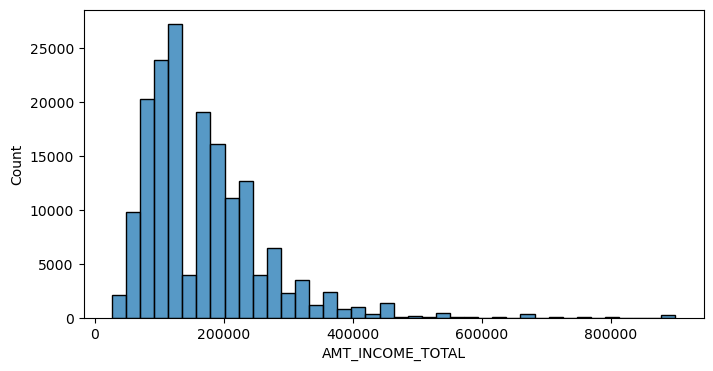

In [37]:
plt.figure(figsize = (8,4))
sns.histplot(data = train, x = 'AMT_INCOME_TOTAL', bins = 40)

#### 4.1.2 DAYS_EMPLOYED -> to substitute values > 300000 for NaN

Replace the 365243 placeholder (indicating pensioners/unemployed) with np.nan so tree-based models handle missing employment durations natively without distorting numeric ratios.

In [38]:
print(f"Train DAYS_EMPLOYED = 365243: {(train['DAYS_EMPLOYED'] == 365243).sum()}")
print(f"Test DAYS_EMPLOYED = 365243:  {(test['DAYS_EMPLOYED'] == 365243).sum()}")

Train DAYS_EMPLOYED = 365243: 30898
Test DAYS_EMPLOYED = 365243:  10565


In [39]:
train['DAYS_EMPLOYED'] = train['DAYS_EMPLOYED'].replace(365243, np.nan)
test['DAYS_EMPLOYED'] = test['DAYS_EMPLOYED'].replace(365243, np.nan)

<Axes: xlabel='DAYS_EMPLOYED', ylabel='Count'>

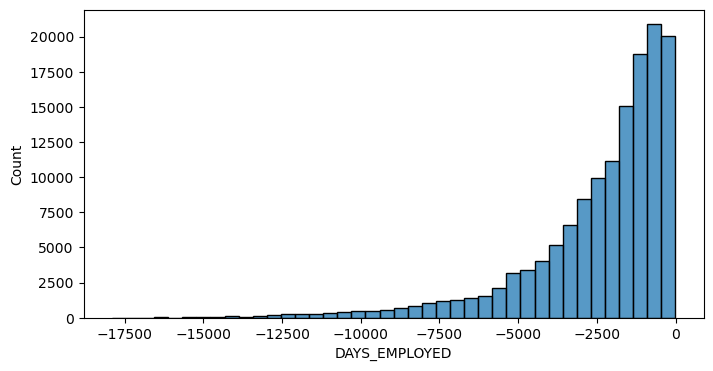

In [40]:
plt.figure(figsize = (8,4))
sns.histplot(data = train, x = 'DAYS_EMPLOYED', bins = 40)

#### 4.1.3 OWN_CAR_AGE -> to substitute values > 60 for NaN

Replace anomalous values above 60 with np.nan, preserving the original structural NaN entries.

In [41]:
print(f"Train OWN_CAR_AGE > 60: {(train['OWN_CAR_AGE'] > 60).sum()}")
print(f"Test OWN_CAR_AGE > 60:  {(test['OWN_CAR_AGE'] > 60).sum()}")

Train OWN_CAR_AGE > 60: 1826
Test OWN_CAR_AGE > 60:  673


In [42]:
train.loc[train['OWN_CAR_AGE'] > 60, 'OWN_CAR_AGE'] = np.nan 
test.loc[test['OWN_CAR_AGE'] > 60, 'OWN_CAR_AGE'] = np.nan 

<Axes: xlabel='OWN_CAR_AGE', ylabel='Count'>

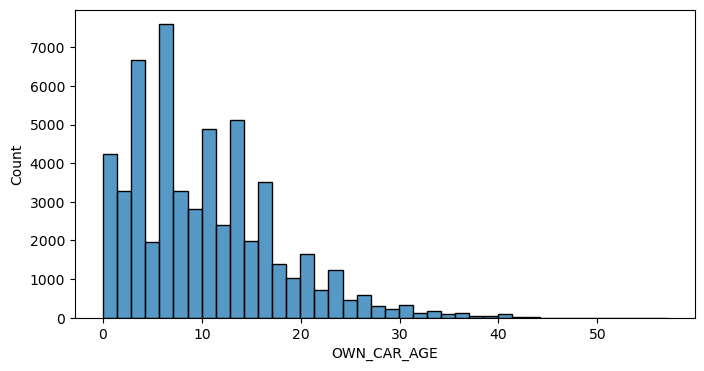

In [43]:
plt.figure(figsize = (8,4))
sns.histplot(data = train, x = 'OWN_CAR_AGE', bins = 40)

#### 4.1.4 CODE_GENDER -> to substitute the residual XNA with mode 'F'

In [44]:
print(f"Train CODE_GENDER XNA: {(train['CODE_GENDER'] == 'XNA').sum()}")
print(f"Test CODE_GENDER XNA:  {(test['CODE_GENDER'] == 'XNA').sum()}")

Train CODE_GENDER XNA: 4
Test CODE_GENDER XNA:  0


In [45]:
train.loc[train['CODE_GENDER'] == 'XNA', 'CODE_GENDER'] = 'F'

<Axes: xlabel='CODE_GENDER', ylabel='Count'>

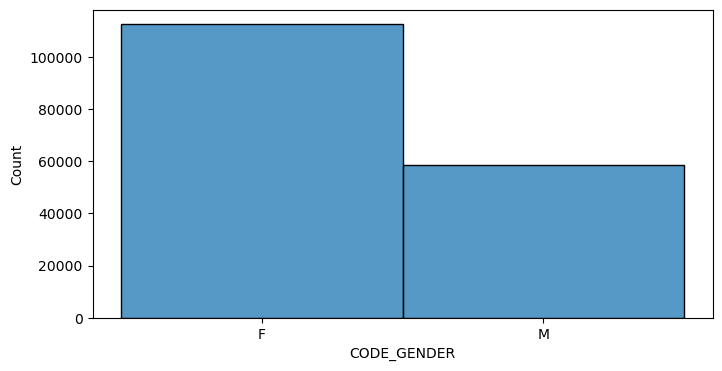

In [46]:
plt.figure(figsize = (8,4))
sns.histplot(data = train, x = 'CODE_GENDER', bins = 40)

#### 4.1.5 NAME_INCOME_TYPE -> agreggate 4 rare categories in 'Other'

In [47]:
print("Train registers: ")
print(train['NAME_INCOME_TYPE'].value_counts(), '\n')
print("Test registers:")
print(test['NAME_INCOME_TYPE'].value_counts())

Train registers: 
Working                 88268
Commercial associate    40007
Pensioner               30895
State servant           12007
Unemployed                 10
Student                     9
Businessman                 3
Maternity leave             3
Name: NAME_INCOME_TYPE, dtype: int64 

Test registers:
Working                 32460
Commercial associate    14253
Pensioner               10560
State servant            4215
Unemployed                  6
Student                     4
Maternity leave             1
Businessman                 1
Name: NAME_INCOME_TYPE, dtype: int64


In [48]:
other = ['Unemployed', 'Student', 'Businessman', 'Maternity leave']
train['NAME_INCOME_TYPE'] = train['NAME_INCOME_TYPE'].apply(lambda x: x.replace(x, 'Other') if x in other else x)

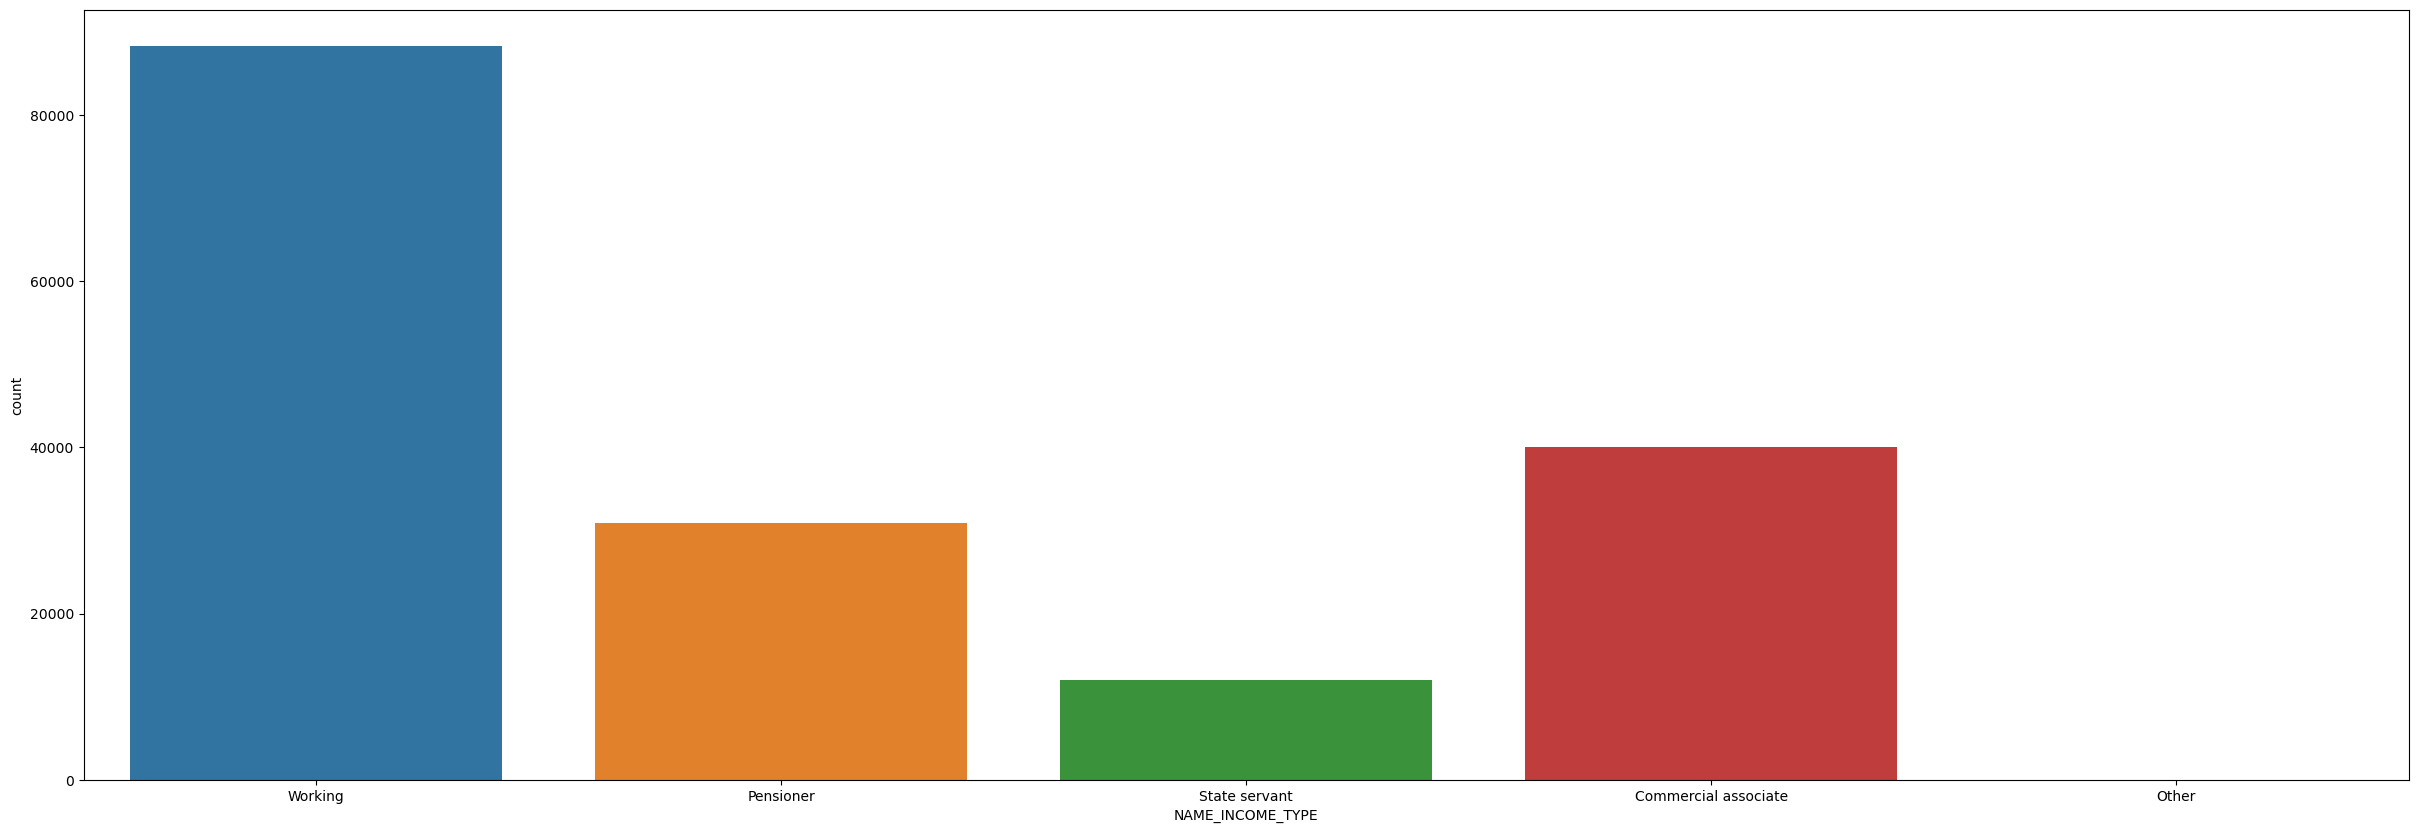

In [49]:
plt.figure(figsize = (30,10))
sns.countplot(data = train, x = "NAME_INCOME_TYPE")
plt.show()

#### 4.1.6 OCCUPATION_TYPE -> Agreggate professions with less than 1500 records in two domais blocks:
- 'Other_Office_Staff': IT staff, HR staff, Realty agents, Secretaries.
- 'Other_Service_Labor': Waiters/barmen staff, Low-skill Laborers, Private service staff.

In [50]:
print("Train registers: ")
print(train['OCCUPATION_TYPE'].value_counts(), '\n')
print("Test registers:")
print(test['OCCUPATION_TYPE'].value_counts())

Train registers: 
Other                    53745
Laborers                 30723
Sales staff              17793
Core staff               15271
Managers                 11855
Drivers                  10353
High skill tech staff     6385
Accountants               5506
Medicine staff            4744
Security staff            3752
Cooking staff             3353
Cleaning staff            2567
Private service staff     1457
Low-skill Laborers        1158
Secretaries                762
Waiters/barmen staff       747
Realty agents              416
HR staff                   309
IT staff                   306
Name: OCCUPATION_TYPE, dtype: int64 

Test registers:
Other                    18734
Laborers                 11490
Sales staff               6604
Core staff                5437
Managers                  4245
Drivers                   3844
High skill tech staff     2219
Accountants               1882
Medicine staff            1668
Security staff            1378
Cooking staff             118

In [51]:
office_rare = ['Secretaries', 'Realty agents', 'HR staff', 'IT staff']
service_rare = ['Private service staff', 'Low-skill Laborers','Waiters/barmen staff']

train['OCCUPATION_TYPE'] = train['OCCUPATION_TYPE'].replace(office_rare, 'Other_Office_Staff')
train['OCCUPATION_TYPE'] = train['OCCUPATION_TYPE'].replace(service_rare, 'Other_Service_Labor')

test['OCCUPATION_TYPE'] = test['OCCUPATION_TYPE'].replace(office_rare, 'Other_Office_Staff')
test['OCCUPATION_TYPE'] = test['OCCUPATION_TYPE'].replace(service_rare, 'Other_Service_Labor')

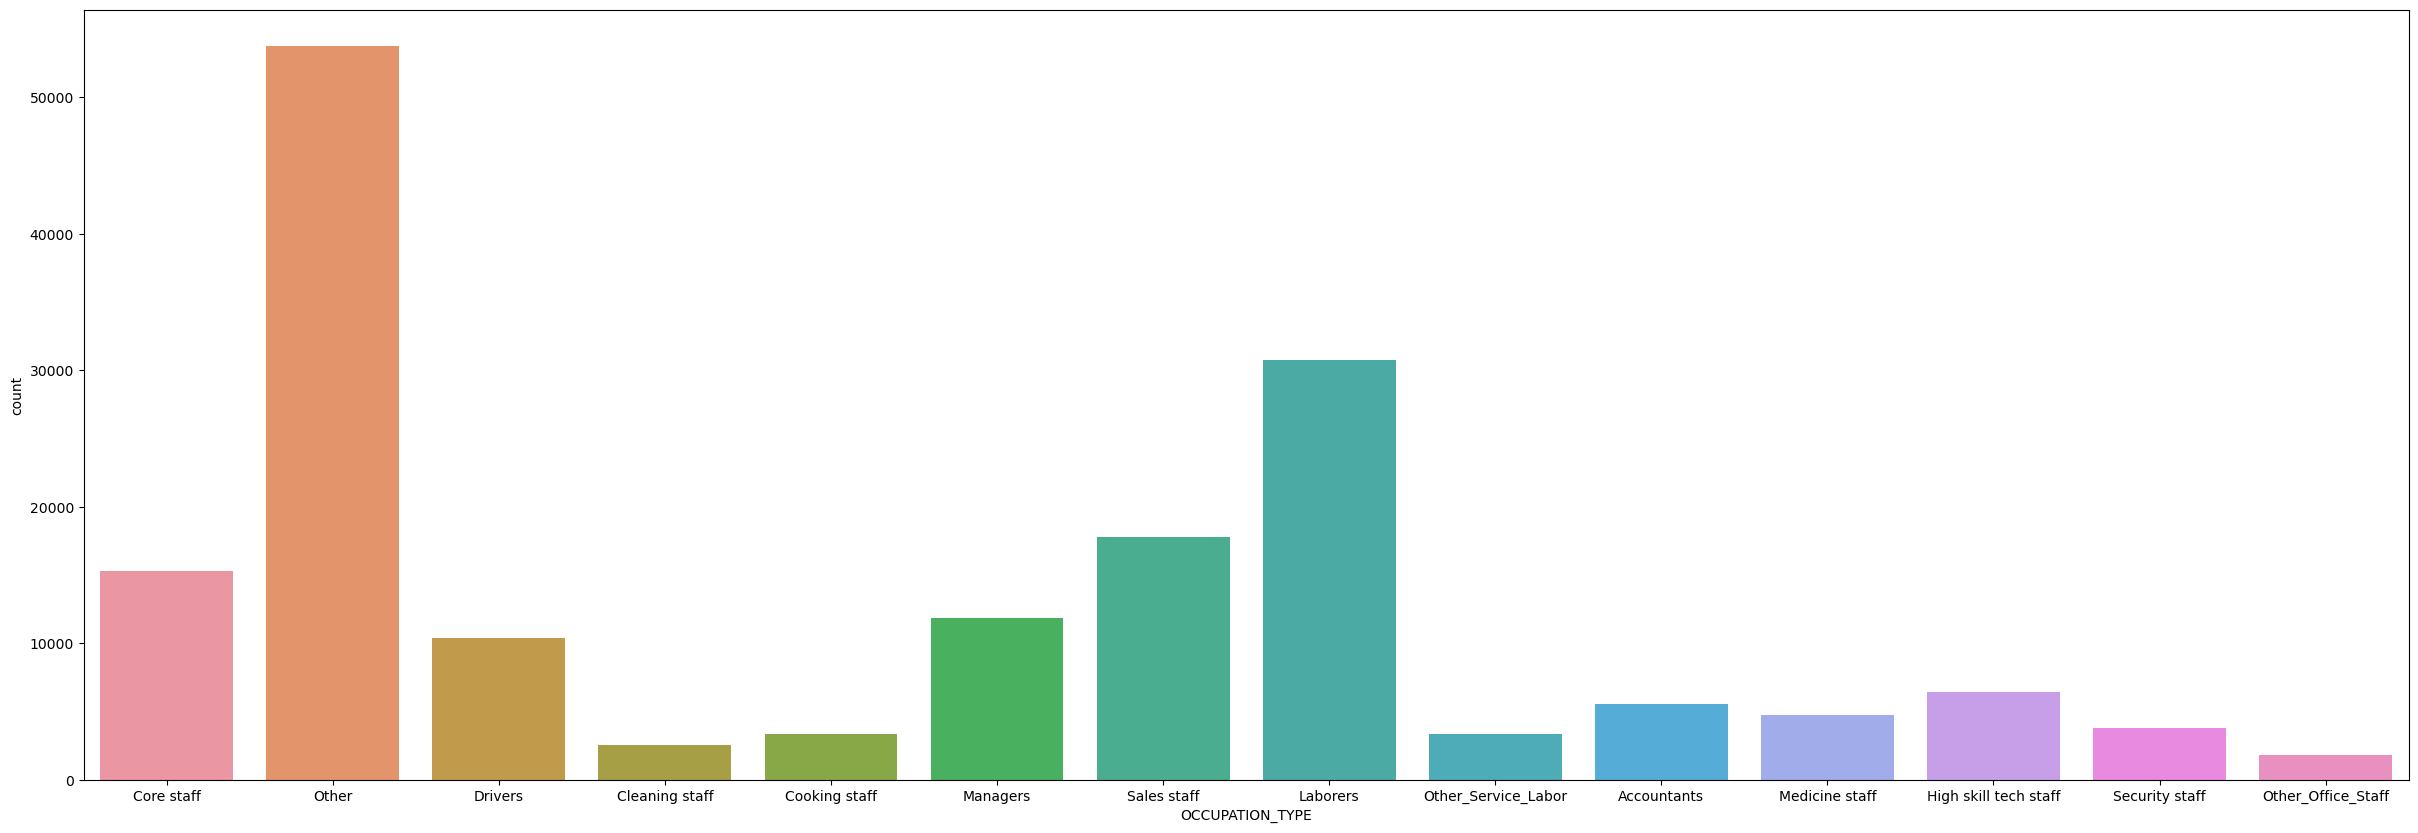

In [52]:
plt.figure(figsize = (30,10))
sns.countplot(data = train, x = "OCCUPATION_TYPE")
plt.show()

#### 4.1.7 ORGANIZATION_TYPE -> reduce the 58 categories to approximately 18 macro-sectors without excessively inflating the 'Other' category:
- Rename 'XNA' (~30,800 records) to 'Unemployed_Pensioner'
- Consolidate fragmented subcategories identified by numbers (Industry: type 1..13, Trade: type 1..7, Transport: type 1..4, Business Entity Type 1..3) into their respective parent sectors ('Industry', 'Trade', 'Transport', 'Business Entity').
- Group the remaining micro-organizations (fewer than 1,000 records) into 'Rare_Organization'.

In [53]:
# RENAME 'XNA' to 'Unemployed_Pensioner
train['ORGANIZATION_TYPE'] = train['ORGANIZATION_TYPE'].replace('XNA', 'Unemployed_Pensioner')
test['ORGANIZATION_TYPE'] = test['ORGANIZATION_TYPE'].replace('XNA', 'Unemployed_Pensioner')

In [54]:
# Consolidate fragmented subcategories 
for prefix in ['Trade', 'Industry', 'Transport', 'Business Entity']:
  train.loc[train['ORGANIZATION_TYPE'].str.startswith(prefix, na=False),'ORGANIZATION_TYPE'] = prefix
  test.loc[test['ORGANIZATION_TYPE'].str.startswith(prefix, na=False),'ORGANIZATION_TYPE'] = prefix

In [55]:
# Group the remaining micro-organizations
org_counts = train['ORGANIZATION_TYPE'].value_counts()
rare_orgs = org_counts[org_counts < 1000].index

train['ORGANIZATION_TYPE'] = train['ORGANIZATION_TYPE'].replace(rare_orgs, 'Rare_Organization')
test['ORGANIZATION_TYPE'] = test['ORGANIZATION_TYPE'].replace(rare_orgs, 'Rare_Organization')

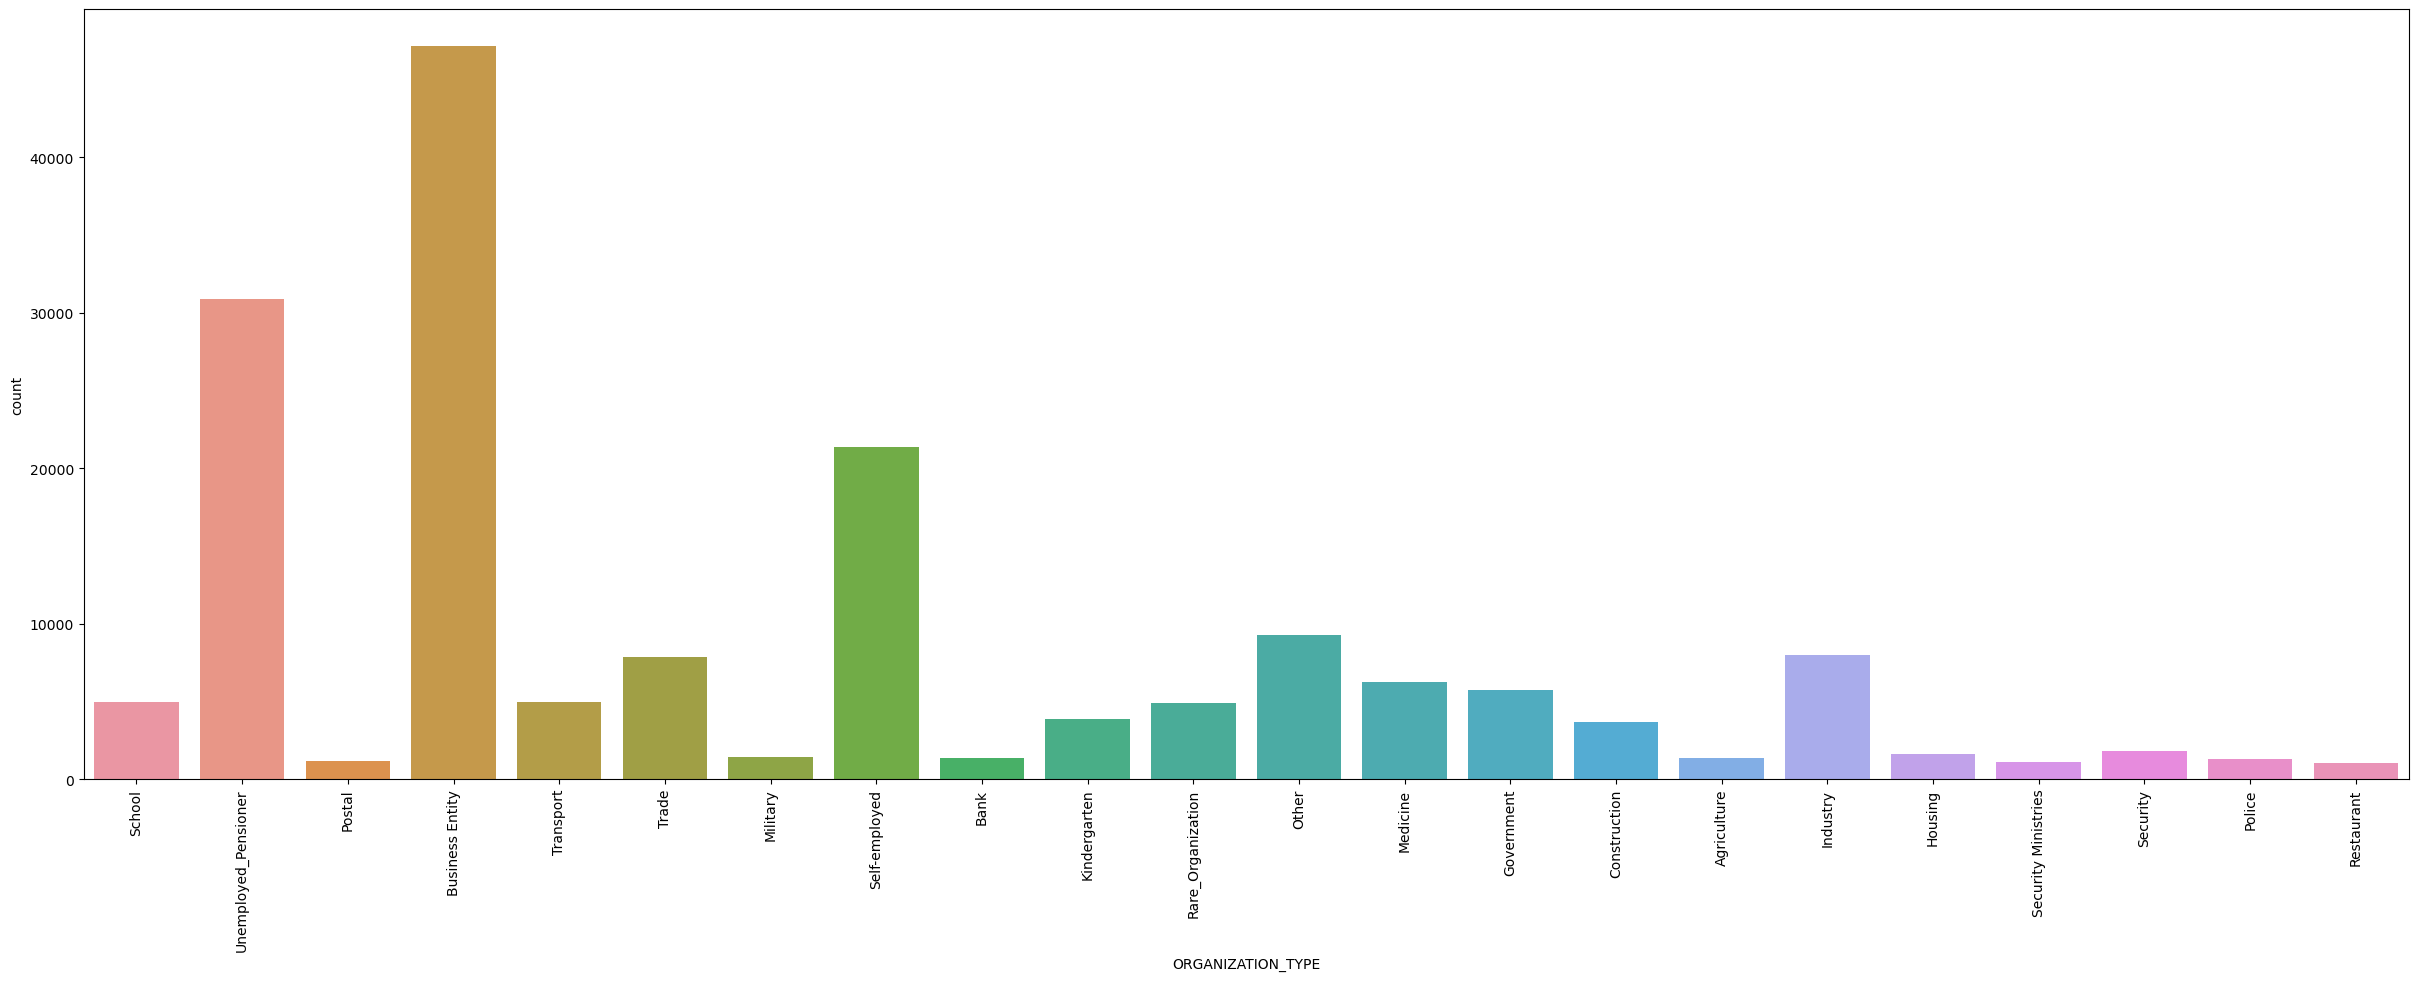

In [56]:
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

### 4.2 Categorical Encoding

In [57]:
def encode_categorical_features(train_df, test_df):
    train_enc = train_df.copy()
    test_enc = test_df.copy()

    # Binary Encoder (CODE_GENDER and NAME_CONTRACT_TYPE)
    gender_map = {'F':0, 'M':1}
    contract_map = {'Cash loans': 0, 'Revolving loans': 1}

    for df in [train_enc, test_enc]:
        df['CODE_GENDER'] = df['CODE_GENDER'].map(gender_map)
        df['NAME_CONTRACT_TYPE'] = df['NAME_CONTRACT_TYPE'].map(contract_map)

    # Ordinal Encoding (NAME_EDUCATION_TYPE)
    education_map = {
      'Lower secondary': 0,
      'Secondary / secondary special': 1,
      'Incomplete higher': 2,
      'Higher education': 3,
      'Academic degree': 4
    }
    for df in [train_enc, test_enc]:
        df['NAME_EDUCATION_TYPE'] = df['NAME_EDUCATION_TYPE'].map(education_map)

    # One-Hot Encoding (NAME_INCOME_TYPE)
    ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

    train_income_ohe = pd.DataFrame(
      ohe.fit_transform(train_enc[['NAME_INCOME_TYPE']]),
      columns=ohe.get_feature_names_out(['NAME_INCOME_TYPE']),
      index=train_enc.index
    )
    test_income_ohe = pd.DataFrame(
      ohe.transform(test_enc[['NAME_INCOME_TYPE']]),
      columns=ohe.get_feature_names_out(['NAME_INCOME_TYPE']),
      index=test_enc.index
    )

    train_enc = pd.concat([train_enc.drop(columns=['NAME_INCOME_TYPE']), train_income_ohe], axis=1)
    test_enc = pd.concat([test_enc.drop(columns=['NAME_INCOME_TYPE']), test_income_ohe], axis=1)

    # Out-of_Fold Target Encoding (OCCUPATION_TYPE and ORGANIZATION_TYPE)
    high_card_cols = ['OCCUPATION_TYPE', 'ORGANIZATION_TYPE']
    te = TargetEncoder(cv=5, smooth='auto', random_state=42)

    train_enc[high_card_cols] = te.fit_transform(train_enc[high_card_cols], train_enc['TARGET'])
    test_enc[high_card_cols] = te.transform(test_enc[high_card_cols])

    return train_enc, test_enc

In [58]:
train, test = encode_categorical_features(train, test)

In [59]:
print(f'Train shape after encoding: {train.shape}')
print(f'Test shape after encoding: {test.shape} \n')

print('Remaining object columns (train):' f"{train.select_dtypes(include='object').columns.tolist()}")
print('Remaining object columns (test):' f"{test.select_dtypes(include='object').columns.tolist()}")

Train shape after encoding: (171202, 24)
Test shape after encoding: (61500, 23) 

Remaining object columns (train):[]
Remaining object columns (test):[]


### 4.3 Handling Missing Values

In [60]:
train.isnull().sum()

EXT_SOURCE_1                             118928
EXT_SOURCE_2                                369
EXT_SOURCE_3                              54586
AMT_CREDIT                                    0
AMT_ANNUITY                                   0
AMT_INCOME_TOTAL                              0
AMT_GOODS_PRICE                               0
DAYS_BIRTH                                    0
DAYS_EMPLOYED                             30898
DAYS_ID_PUBLISH                               0
DAYS_LAST_PHONE_CHANGE                        0
NAME_EDUCATION_TYPE                           0
CODE_GENDER                                   0
NAME_CONTRACT_TYPE                            0
OCCUPATION_TYPE                               0
OWN_CAR_AGE                              114818
ORGANIZATION_TYPE                             0
REGION_RATING_CLIENT                          0
TARGET                                        0
NAME_INCOME_TYPE_Commercial associate         0
NAME_INCOME_TYPE_Other                  

Each feature has a different form to handling missing values:

- `EXT_SOURCE_2`: Very small absence; the median is more reliable than the mean because of the slight left skewness.
- `EXT_SOURCE_1` and `EXT_SOURCE_3`: Median + Absence Flag (_IS_MISSING) - The absence indicates a thin-file client (MNAR); the flag preserves this risk signal.
- `DAYS_EMPLOYED`: Input with 0 + Flag (DAYS_EMPLOYED_ANOM) - All of these NaN values ​​came from code above 300000 (retired/unemployed). Filling in 0 (zero days worked) makes much more business sense than assigning the median to a retiree.
- `OWN_CAR_AGE`: group OWN_CAR_AGE by decade (e.g. Group 1: 0-9 years, Group 2: 10-19 years, NaN: -1, etc), and use (clip(upper = 3)) to aggregate cars more older than 30 years (because they are rare and using Ohe it will be create some columns with so much zeros) then apply One Hot Encoding.

In [61]:
def handle_missing_values(train_df, test_df):
    train_hmv = train_df.copy() 
    test_hmv = test_df.copy()

    # EXT_SOURCE_2
    ext2_median = train_hmv['EXT_SOURCE_2'].median()
    train_hmv['EXT_SOURCE_2'] = train_hmv['EXT_SOURCE_2'].fillna(ext2_median)
    test_hmv['EXT_SOURCE_2'] = test_hmv['EXT_SOURCE_2'].fillna(ext2_median)

    # EXT_SOURCE_1 and EXT_SOURCE_3
    for col in ['EXT_SOURCE_1', 'EXT_SOURCE_3']:
        median_val = train_hmv[col].median()
        for df in [train_hmv, test_hmv]:
            df[f'{col}_IS_MISSING'] = df[col].isnull().astype(int)
            df[col] = df[col].fillna(median_val)

    # DAYS_EMPLOYED
    for df in [train_hmv, test_hmv]:
        df['DAYS_EMPLOYED_ANOM'] = df['DAYS_EMPLOYED'].isnull().astype(int)
        df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].fillna(0)

    # OWN_CAR_AGE
    for df in [train_hmv, test_hmv]:
        df['OWN_CAR_AGE'] = (df['OWN_CAR_AGE'] // 10).clip(upper=3).fillna(-1).astype(int)

    ohe_car = OneHotEncoder(sparse_output = False, handle_unknown = 'ignore')
    train_car_ohe = pd.DataFrame(ohe_car.fit_transform(train_hmv[['OWN_CAR_AGE']]),
                                 columns = ohe_car.get_feature_names_out(['OWN_CAR_AGE']),
                                 index = train_hmv.index)
    test_car_ohe = pd.DataFrame(ohe_car.transform(test_hmv[['OWN_CAR_AGE']]),
                                columns = ohe_car.get_feature_names_out(['OWN_CAR_AGE']),
                                index = test_hmv.index)

    train_hmv = pd.concat([train_hmv.drop(columns = ['OWN_CAR_AGE']), train_car_ohe], axis = 1)
    test_hmv = pd.concat([test_hmv.drop(columns = ['OWN_CAR_AGE']), test_car_ohe], axis = 1)

    # Treate spaces in column names
    train_hmv.columns = train_hmv.columns.str.replace(' ', '_', regex = False)
    test_hmv.columns = test_hmv.columns.str.replace(' ', '_', regex = False)

    return train_hmv, test_hmv

In [62]:
train_final, test_final = handle_missing_values(train, test)

In [63]:
print('Total train features NaN remaining:')
print(train_final.isna().sum())

Total train features NaN remaining:
EXT_SOURCE_1                             0
EXT_SOURCE_2                             0
EXT_SOURCE_3                             0
AMT_CREDIT                               0
AMT_ANNUITY                              0
AMT_INCOME_TOTAL                         0
AMT_GOODS_PRICE                          0
DAYS_BIRTH                               0
DAYS_EMPLOYED                            0
DAYS_ID_PUBLISH                          0
DAYS_LAST_PHONE_CHANGE                   0
NAME_EDUCATION_TYPE                      0
CODE_GENDER                              0
NAME_CONTRACT_TYPE                       0
OCCUPATION_TYPE                          0
ORGANIZATION_TYPE                        0
REGION_RATING_CLIENT                     0
TARGET                                   0
NAME_INCOME_TYPE_Commercial_associate    0
NAME_INCOME_TYPE_Other                   0
NAME_INCOME_TYPE_Pensioner               0
NAME_INCOME_TYPE_State_servant           0
NAME_INCOME_TYPE_W

In [64]:
print('Total test features NaN remaining:')
print(test_final.isna().sum())

Total test features NaN remaining:
EXT_SOURCE_1                             0
EXT_SOURCE_2                             0
EXT_SOURCE_3                             0
AMT_CREDIT                               0
AMT_ANNUITY                              0
AMT_INCOME_TOTAL                         0
AMT_GOODS_PRICE                          0
DAYS_BIRTH                               0
DAYS_EMPLOYED                            0
DAYS_ID_PUBLISH                          0
DAYS_LAST_PHONE_CHANGE                   0
NAME_EDUCATION_TYPE                      0
CODE_GENDER                              0
NAME_CONTRACT_TYPE                       0
OCCUPATION_TYPE                          0
ORGANIZATION_TYPE                        0
REGION_RATING_CLIENT                     0
NAME_INCOME_TYPE_Commercial_associate    0
NAME_INCOME_TYPE_Other                   0
NAME_INCOME_TYPE_Pensioner               0
NAME_INCOME_TYPE_State_servant           0
NAME_INCOME_TYPE_Working                 0
EXT_SOURCE_1_IS_MIS

In [65]:
print('TRAIN COLUMNS')
print(train.columns)

print('\nTEST COLUMNS')
print(test.columns)

TRAIN COLUMNS
Index(['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AMT_CREDIT',
       'AMT_ANNUITY', 'AMT_INCOME_TOTAL', 'AMT_GOODS_PRICE', 'DAYS_BIRTH',
       'DAYS_EMPLOYED', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE',
       'NAME_EDUCATION_TYPE', 'CODE_GENDER', 'NAME_CONTRACT_TYPE',
       'OCCUPATION_TYPE', 'OWN_CAR_AGE', 'ORGANIZATION_TYPE',
       'REGION_RATING_CLIENT', 'TARGET',
       'NAME_INCOME_TYPE_Commercial associate', 'NAME_INCOME_TYPE_Other',
       'NAME_INCOME_TYPE_Pensioner', 'NAME_INCOME_TYPE_State servant',
       'NAME_INCOME_TYPE_Working'],
      dtype='object')

TEST COLUMNS
Index(['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AMT_CREDIT',
       'AMT_ANNUITY', 'AMT_INCOME_TOTAL', 'AMT_GOODS_PRICE', 'DAYS_BIRTH',
       'DAYS_EMPLOYED', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE',
       'NAME_EDUCATION_TYPE', 'CODE_GENDER', 'NAME_CONTRACT_TYPE',
       'OCCUPATION_TYPE', 'OWN_CAR_AGE', 'ORGANIZATION_TYPE',
       'REGION_RATING_CLIENT', 'NAME_INCOME_

In [87]:
from pathlib import Path

processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)

train_final.to_csv(processed_dir / "train_final.csv", index=False)
test_final.to_csv(processed_dir / "test_final.csv", index=False)

print(f"train_final: {train_final.shape}")
print(f"test_final:  {test_final.shape}")

train_final: (171202, 31)
test_final:  (61500, 30)
